# 调用线上的大模型
## 1、调用具体模型厂商的API
### 1.1 调用DeepSeek官网的DeepSeek模型
调用大模型涉及到三个特别重要的参数：
base_url、model_name、API_KEY
举例1：将参数信息存储在.env配置文件中 并直接在代码中引用

In [1]:
from dashscope import api_key
from pydantic import SecretStr
import os

from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek


# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)

DEEPSEEK_API_KEY=SecretStr(os.getenv("DEEPSEEK_API_KEY")or"")
DEEPSEEK_BASE_URL=os.getenv("DEEPSEEK_BASE_URL") or ""

# 2、模型的初始化
llm_deepseek=ChatDeepSeek(
    model="deepseek-flash",
    api_key=DEEPSEEK_API_KEY,
    api_base=DEEPSEEK_BASE_URL,

)
# 3、模型的调用
response=llm_deepseek.invoke("请用一句话介绍你自己")
print(response)

content='我是DeepSeek，由深度求索公司打造的AI助手，能帮你解答问题、处理信息并完成多种任务。' additional_kwargs={'refusal': None, 'reasoning_content': '我们需要回答中文。用户要求“请用一句话介绍你自己”。需要一句话。应该简洁，不要展开。可以：“我是DeepSeek，由深度求索公司打造的AI助手，能帮你解答问题、处理信息和完成多种任务。” 一句话。注意不要提不能做的？简单。 final only.'} response_metadata={'token_usage': {'completion_tokens': 90, 'prompt_tokens': 35, 'total_tokens': 125, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 63, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 35}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501', 'id': 'e662cdf8-9fdd-4e17-8d15-c42cf322bf2a', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a17809-4005-78c3-8657-f5ba121b4e58-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 35, 'output_tokens': 90, 'total_tokens': 125, '

举例2：将参数信息存储在.env配置文件中 代码中不声明 会默认从配置文件中引入

In [ ]:


from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek
# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)

# DEEPSEEK_API_KEY=os.getenv("DEEPSEEK_API_KEY")
# DEEPSEEK_BASE_URL=os.getenv("DEEPSEEK_BASE_URL")
# 2、模型的初始化
llm_deepseek=ChatDeepSeek(
    model="deepseek-flash",
    # api_key=DEEPSEEK_API_KEY,
    # api_base=DEEPSEEK_BASE_URL,

)
# 3、模型的调用
response=llm_deepseek.invoke("请用一句话介绍你自己")
print(response)

### 1.2 兼容写法 ChatOpenAI

举例1：调用Deepseek官网通用大模型

In [3]:
from langchain_openai import ChatOpenAI
import  os
# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)

DEEPSEEK_API_KEY=SecretStr(os.getenv("DEEPSEEK_API_KEY") or "")
DEEPSEEK_BASE_URL=os.getenv("DEEPSEEK_BASE_URL")
# 2、模型的初始化
llm_deepseek=ChatOpenAI(
    model="deepseek-flash",
    api_key=DEEPSEEK_API_KEY,
    ## 必须写
    base_url=DEEPSEEK_BASE_URL,

)
# 3、模型的调用
print(llm_deepseek.invoke("1+1等于几"))


KeyboardInterrupt: 

### 1.3使用OpenRouter作为中转平台


In [2]:
import os
from pydantic import SecretStr
from dotenv import load_dotenv
from langchain_openrouter import ChatOpenRouter

# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)
OPENROUTER_API_KEY=SecretStr(os.getenv("OPENROUTER_API_KEY")or"")

# 2、模型的初始化
model=ChatOpenRouter(
    model="google/gemma-4-26b-a4b-it:free",
    api_key=OPENROUTER_API_KEY,

)
# 3、模型的调用
response=model.invoke("请用一句话介绍你自己，用中文")
print(response)

content='我是 Gemma 4，是由 Google DeepMind 开发的开源权重大型语言模型。' additional_kwargs={} response_metadata={'model_name': 'google/gemma-4-26b-a4b-it:free', 'id': 'gen-1791704893-w0SH7S1IsVSfNVrAuTJ8', 'created': 1791704893, 'object': 'chat.completion', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'openrouter'} id='lc_run--01a129ee-fd54-7f42-9489-646c7f56ce5e-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 10, 'output_tokens': 17, 'total_tokens': 27, 'input_token_details': {'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'reasoning': 0}}


### 1.4 使用closeai作为中转平台

In [ ]:
import os

from dotenv import load_dotenv


# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)
CLOSE_API_KEY=SecretStr(os.getenv("CLOSE_API_KEY")or"")
CLOSE_BASE_URL=os.getenv("CLOSE_BASE_URL")
# 2、模型的初始化
model=ChatOpenAI(
    model="gpt-image-2",
    api_key=CLOSE_API_KEY,
    base_url=CLOSE_BASE_URL,

)
# 3、模型的调用
response=model.invoke("请用一句话介绍你自己，用中文")
print(response)

# 2、使用langchain1.x的统一方式

使用init_chat_mode()

举例1：调用deepseek官网的DeepSeek模型



In [1]:
import os
from pydantic import SecretStr
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv


# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)
DEEPSEEK_API_KEY=SecretStr(os.getenv("DEEPSEEK_API_KEY")or"")
DEEPSEEK_BASE_URL=os.getenv("DEEPSEEK_BASE_URL")
# 2、模型的初始化
model=init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    #或者
   #model="deepseek:deepseek-flash",
    api_key=DEEPSEEK_API_KEY,
    base_url=DEEPSEEK_BASE_URL,

)
# 3、模型的调用
response=model.invoke("请用一句话介绍你自己，用中文")
print(response)

content='我是由深度求索公司开发的AI助手DeepSeek，能用中文为你提供信息与帮助。' additional_kwargs={'refusal': None, 'reasoning_content': '我们需要回答用户中文请求：“请用一句话介绍你自己，用中文”。需要一句话介绍自己。应简洁。可以说：我是由深度求索公司开发的AI助手DeepSeek，能用中文为你提供信息和帮助。这是一句话。注意中文。不能多说。确保一句话。用中文。'} response_metadata={'token_usage': {'completion_tokens': 82, 'prompt_tokens': 38, 'total_tokens': 120, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 60, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 38}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501', 'id': 'ab263a87-a114-4208-bb12-3da09453cac0', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a167cf-afb6-73e2-b3a1-7e0dd8c5f586-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 38, 'output_tokens': 82, 'total_tokens': 120, 'input_token_detai

# 3、小结
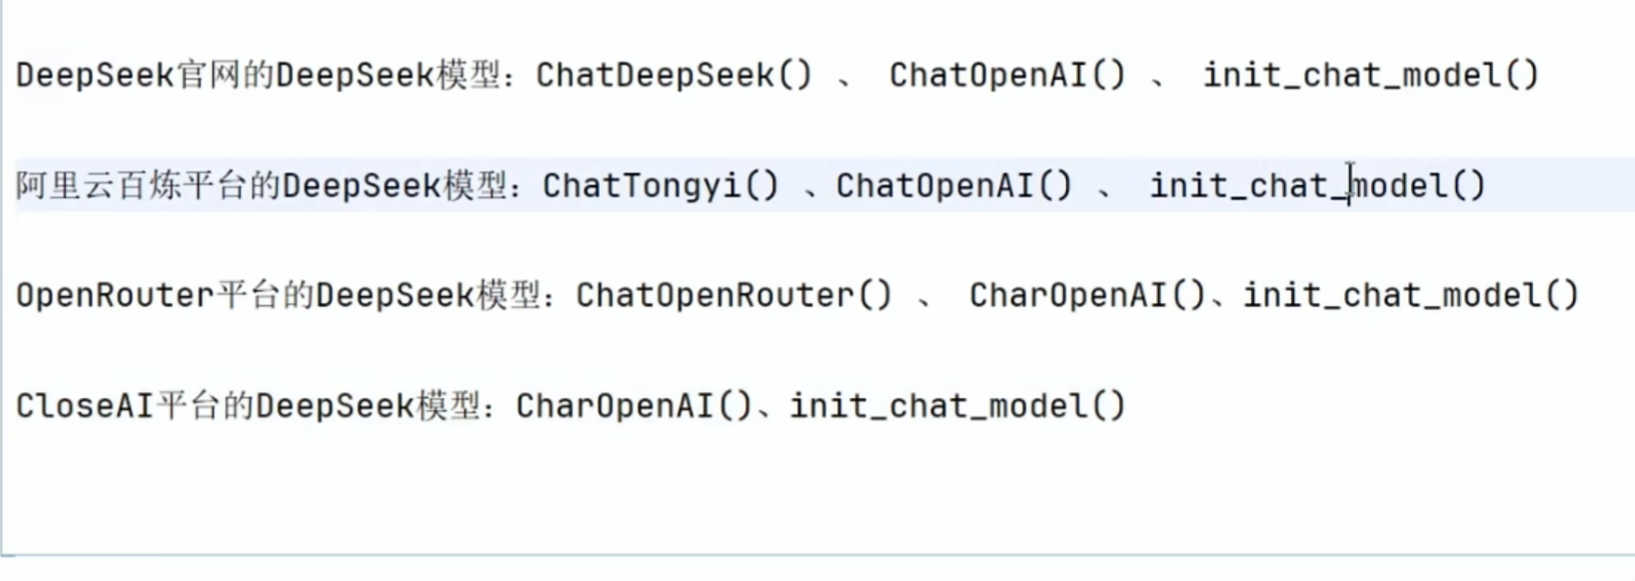